# Homework07

Exercises to practice pandas, data analysis and regression

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different regression models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor

from data_utils import object_from_json_url
from data_utils import regression_error

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/DM-GY-9103-2024F-H/WK02).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [3]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

#### Nested data

This is that *nested* dataset from Week 02.

# 🤔

Let's load it into a `DataFrame` to see what happens.

In [4]:
# Read into DataFrame
ansur_df = pd.DataFrame.from_records(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear,foot,hand,head
0,18,F,66,135,1699,1645,"{'breadth': 30, 'length': 61, 'protrusion': 20}","{'breadth': 97, 'length': 243}","{'breadth': 78, 'length': 182, 'palm': 108}","{'height': 243, 'circumference': 557}"
1,30,M,68,207,1749,1715,"{'breadth': 35, 'length': 63, 'protrusion': 17}","{'breadth': 100, 'length': 252}","{'breadth': 87, 'length': 184, 'palm': 114}","{'height': 238, 'circumference': 560}"
2,27,M,67,121,1684,1657,"{'breadth': 36, 'length': 59, 'protrusion': 24}","{'breadth': 92, 'length': 251}","{'breadth': 84, 'length': 180, 'palm': 103}","{'height': 239, 'circumference': 516}"
3,20,M,73,185,1878,1828,"{'breadth': 36, 'length': 60, 'protrusion': 21}","{'breadth': 104, 'length': 280}","{'breadth': 95, 'length': 201, 'palm': 124}","{'height': 270, 'circumference': 582}"
4,33,M,76,150,1977,1883,"{'breadth': 39, 'length': 65, 'protrusion': 27}","{'breadth': 101, 'length': 271}","{'breadth': 90, 'length': 194, 'palm': 113}","{'height': 254, 'circumference': 559}"



# 😓🙄

That didn't work too well. We ended up with objects in our columns.

Luckily, our `DataFrame` library has a function called [`json_normalize()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.json_normalize.html) that can help.

In [5]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


Much better. `DataFrames` are magic.

#### Data Exploration

Before we start creating models, let's do a little bit of data analysis and get a feeling for the shapes, distributions and relationships of our data.

1. Print `min`, `max` and `average` values for all of the features.
2. Print `covariance` tables for `age`, `ear.length` and `head.circumference`.
3. Plot `age`, `ear.length` and `head.circumference` versus the $1$ *feature* that is most correlated to each of them.

Don't forget to *encode* and *normalize* the data.

Minimum values:


,0
age,17
height,56
weight,0
span,1323
stature,1409
ear.breadth,25
ear.length,46
ear.protrusion,13
foot.breadth,77
foot.length,198


Maximum values:


,0
age,58
height,94
weight,321
span,2121
stature,1993
ear.breadth,46
ear.length,81
ear.protrusion,34
foot.breadth,126
foot.length,323


Average values:


,0
age,29.745357
height,68.247321
weight,174.558393
span,1763.703393
stature,1714.265357
ear.breadth,35.128929
ear.length,62.637143
ear.protrusion,22.266786
foot.breadth,98.850893
foot.length,262.991964


... (3 outputs left out)

,ear.length
gender_M,0.029995
ear.length,0.019020
hand.breadth,0.010741
ear.breadth,0.009605
stature,0.009331
age,0.008508
foot.breadth,0.008158
foot.length,0.008047
ear.protrusion,0.007949
span,0.007700


Covariance for head.circumference


,head.circumference
gender_M,0.021971
head.circumference,0.019021
hand.breadth,0.010753
head.height,0.010039
stature,0.009850
foot.length,0.009628
foot.breadth,0.009212
span,0.009145
hand.palm,0.008539
hand.length,0.007832


age is most correlated with ear.length


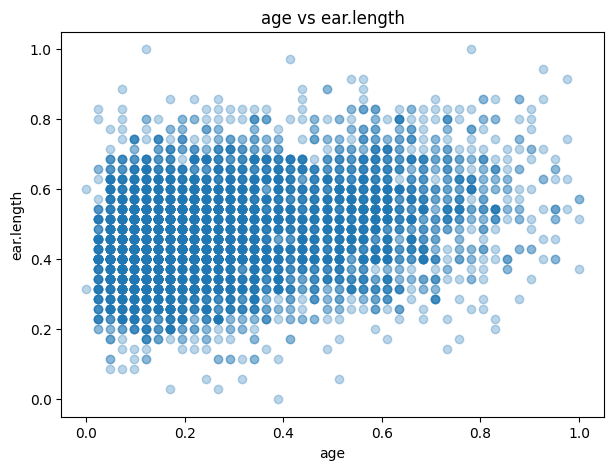

ear.length is most correlated with weight


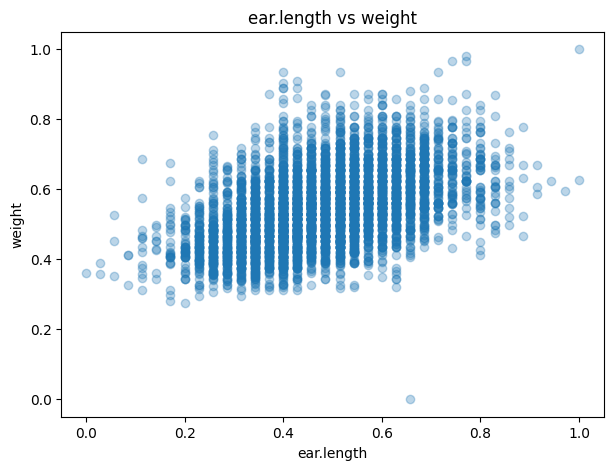

head.circumference is most correlated with head.height


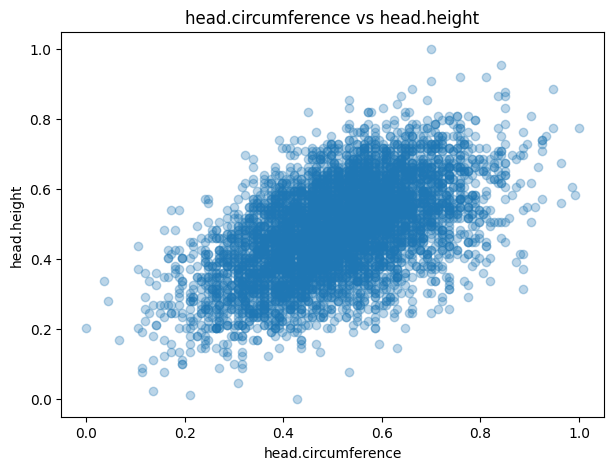

In [6]:

# Work on Data Exploration here

### Encode non-numerical features
ansur_encoded = pd.get_dummies(ansur_df, dtype=int)

# Convert all columns to numeric values
ansur_encoded = ansur_encoded.apply(pd.to_numeric, errors="coerce")

# Remove columns with missing values
ansur_encoded = ansur_encoded.dropna(axis=1)

## 1. Print min, max, avg
print("Minimum values:")
display(ansur_encoded.min())

print("Maximum values:")
display(ansur_encoded.max())

print("Average values:")
display(ansur_encoded.mean())

### Normalize all data
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

ansur_normalized = pd.DataFrame(
    scaler.fit_transform(ansur_encoded),
    columns=ansur_encoded.columns
)

## 2. Print Covariances
cov_matrix = ansur_normalized.cov()

features = ["age", "ear.length", "head.circumference"]

for feature in features:
    print("Covariance for", feature)
    display(cov_matrix[feature].sort_values(ascending=False))

## 3. Plot features most correlated to age, ear length and head circumference
corr_matrix = ansur_normalized.corr()

for feature in features:
    # Find most correlated feature, excluding itself
    most_correlated = (
        corr_matrix[feature]
        .drop(feature)
        .abs()
        .idxmax()
    )

    print(feature, "is most correlated with", most_correlated)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        ansur_normalized[feature],
        ansur_normalized[most_correlated],
        alpha=0.3
    )

    plt.xlabel(feature)
    plt.ylabel(most_correlated)
    plt.title(feature + " vs " + most_correlated)
    plt.show()

### Interpretation

<span style="color:hotpink;">
Does anything stand out about these graphs? Or the correlations?<br>
Are correlations symmetric? Does the feature most correlated to ear length also have ear length as its most correlated pair?
</span>

The graphs show that some body measurements have stronger relationships than others. Features that are closely related in size tend to have higher correlations, while age may have weaker relationships with physical measurements.

Yes, correlations are symmetric. This means the correlation between A and B is always the same as between B and A. However, the feature most correlated with ear length does not necessarily have ear length as its most correlated feature, because it might have a stronger relationship with another measurement.<span style="color:hotpink;">

EDIT THIS CELL WITH ANSWER</span>

### Regression

Now, we want to create a regression model to predict `head.circumference` from the data.

From our [Week 07](https://github.com/PSAM-5020-2026F-A/WK07) notebook, we can create a regression model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (done! ⚡️)
3. Normalize the data (done! 🍾)
4. Separate the outcome variable and the input features
5. Create a regression model using all features
6. Run model on training data and measure error
7. Plot predictions and interpret results
8. Run model on test data, measure error, plot predictions, interpret results

Training Mean Squared Error: 0.011052642216620126
Training R2 Score: 0.4191370744406806


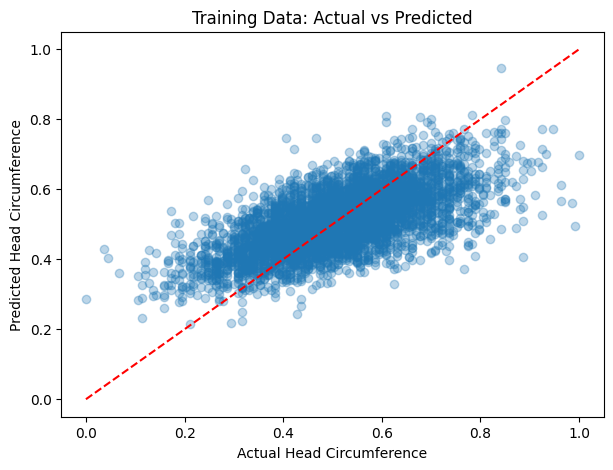

Test Mean Squared Error: 0.010506392711334784
Test R2 Score: 0.4462294876233911


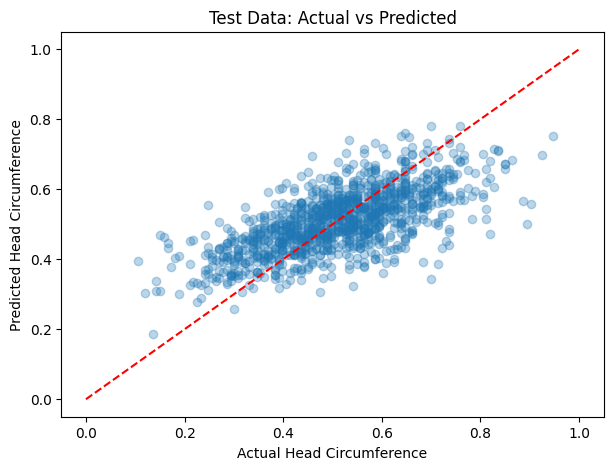

In [7]:

# Work on Regression Model here

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

## Separate outcome variable and input features

X = ansur_normalized.drop(columns=["head.circumference"])
y = ansur_normalized["head.circumference"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create a regression model

model = LinearRegression()
model.fit(X_train, y_train)

## Measure error on training data

train_predictions = model.predict(X_train)

train_error = mean_squared_error(y_train, train_predictions)

print("Training Mean Squared Error:", train_error)
print("Training R2 Score:", r2_score(y_train, train_predictions))

## Plot predictions and interpret results

plt.figure(figsize=(7, 5))

plt.scatter(y_train, train_predictions, alpha=0.3)

plt.plot([0, 1], [0, 1], color="red", linestyle="--")

plt.xlabel("Actual Head Circumference")
plt.ylabel("Predicted Head Circumference")
plt.title("Training Data: Actual vs Predicted")

plt.show()

## Measure error on test data

test_predictions = model.predict(X_test)

test_error = mean_squared_error(y_test, test_predictions)

print("Test Mean Squared Error:", test_error)
print("Test R2 Score:", r2_score(y_test, test_predictions))

## Plot test predictions

plt.figure(figsize=(7, 5))

plt.scatter(y_test, test_predictions, alpha=0.3)

plt.plot([0, 1], [0, 1], color="red", linestyle="--")

plt.xlabel("Actual Head Circumference")
plt.ylabel("Predicted Head Circumference")
plt.title("Test Data: Actual vs Predicted")

plt.show()

Test Mean Squared Error: 0.011809155712547469
Test R2 Score: 0.3300393871675563


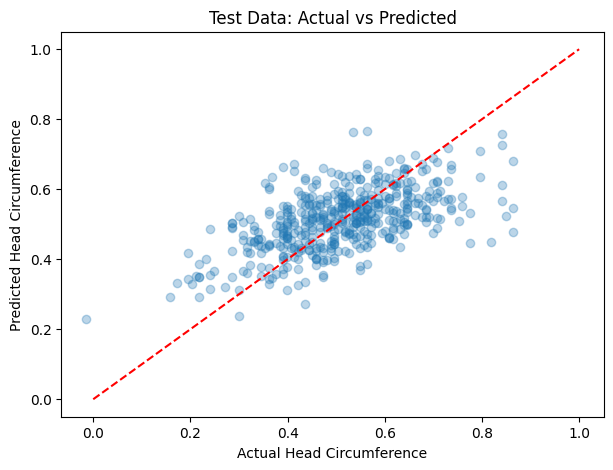

In [9]:

## Load Test Data

ANSUR_TEST_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur-test.json"

ansur_test_data = object_from_json_url(ANSUR_TEST_FILE)
ansur_test_df = pd.json_normalize(ansur_test_data)

# Encode test data
ansur_test_encoded_df = pd.get_dummies(
    ansur_test_df, dtype=int
)

# Match training columns
ansur_test_encoded_df = ansur_test_encoded_df.reindex(
    columns=ansur_encoded.columns,
    fill_value=0
)

# Normalize using the existing training scaler
ansur_test_scaled_df = pd.DataFrame(
    scaler.transform(ansur_test_encoded_df),
    columns=ansur_encoded.columns
)

# Separate input features and outcome
X_test = ansur_test_scaled_df.drop(
    columns=["head.circumference"]
)

y_test = ansur_test_scaled_df["head.circumference"]

# Predict using the trained regression model
test_predictions = model.predict(X_test)

# Calculate error
print("Test Mean Squared Error:",
      mean_squared_error(y_test, test_predictions))

print("Test R2 Score:",
      r2_score(y_test, test_predictions))

# Plot actual vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(y_test, test_predictions, alpha=0.3)

plt.plot([0, 1], [0, 1], "r--")

plt.xlabel("Actual Head Circumference")
plt.ylabel("Predicted Head Circumference")
plt.title("Test Data: Actual vs Predicted")

plt.show()

Test Mean Squared Error: 0.011809155712547469
Test R2 Score: 0.3300393871675563


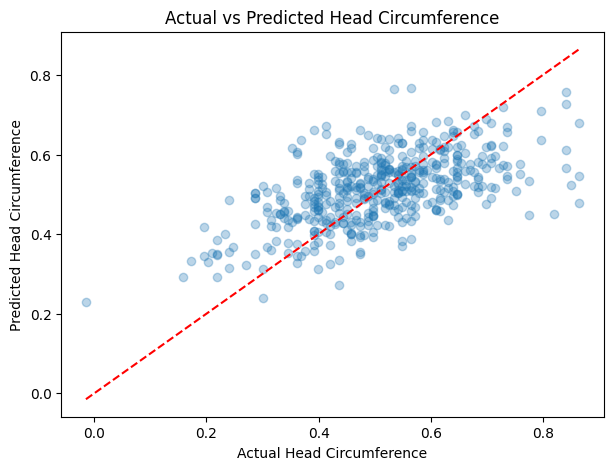

In [10]:

## Run model on test data

X_test = ansur_test_scaled_df.drop(columns=["head.circumference"])
y_test = ansur_test_scaled_df["head.circumference"]

test_predictions = model.predict(X_test)

## Measure error on test data

from sklearn.metrics import mean_squared_error, r2_score

test_error = mean_squared_error(y_test, test_predictions)

print("Test Mean Squared Error:", test_error)
print("Test R2 Score:", r2_score(y_test, test_predictions))

## Plot predictions and interpret results

plt.figure(figsize=(7, 5))

plt.scatter(y_test, test_predictions, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Head Circumference")
plt.ylabel("Predicted Head Circumference")
plt.title("Actual vs Predicted Head Circumference")

plt.show()

### Interpretation

<span style="color:hotpink;">
How well does your model perform?<br>
How could you improve it?<br>
Are there ranges of circumferences that don't get predicted well?
</span>

<span style="color:hotpink;">The model's performance can be evaluated by looking at how close the predicted values are to the actual values. Predictions closer to the red dashed line indicate better accuracy, while points farther away show larger errors.

The model could be improved by selecting the most relevant features, removing unnecessary features, or trying different regression models.

The model may have difficulty predicting very small or very large head circumferences because these values are less common in the dataset. Predictions in the middle range may be more accurate. However, this would need to be confirmed by looking at the graph and comparing the errors across different ranges.</span>